<a href="https://colab.research.google.com/github/Harshini-Bhandary21/AIML_LAB_PRACTICALS/blob/main/Harshini_AIML_Assignment_5_Ensemble_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML Assignment 5

Name: Harshini Ramdas Bhandary  
PRN: 202401040151  
Roll no: 35  
Div: A  Batch: A2  

## 1. Title
Ensemble Learning and Performance Evaluation using Stacking, AdaBoost and Voting Classifiers

## 2. Aim
The aim of this experiment is to build three kinds of ensemble models (Stacking, AdaBoost and Voting) and check how well they work compared to the normal single models used inside them.

Instead of looking only at accuracy, the experiment also checks precision, recall, F1-score and ROC-AUC, so that we can see how each model behaves on both classes of the data.

## 3. Experiment Objectives
1. To load a classification dataset and prepare it for training and testing.
2. To train five single (base) models: Logistic Regression, Decision Tree, KNN, SVM and Naive Bayes.
3. To build a Stacking ensemble where a meta-classifier combines the predictions of the base models.
4. To build an AdaBoost ensemble using different base classifiers.
5. To build a Voting ensemble that takes the majority vote of the base models.
6. To compare all the models using accuracy, precision, recall, F1-score, ROC-AUC, confusion matrix and cross-validation.
7. To write down when each ensemble method is useful and what can be improved further.

## 4. Experiment Outcomes
After running the program, all five base models and all the ensemble models were trained on the same training data and tested on the same test data.

A comparison table was produced for every model. The ensembles did clearly better than the weakest single models, which are the Decision Tree and Naive Bayes.

At the same time, the ensembles did not do better than the best single models on this dataset. Logistic Regression and SVM were just as good, and slightly better on the single test split. The reason for this is explained in the result analysis.

Some extra graphs were also drawn (bar chart, confusion matrices, ROC curves and a cross-validation chart). The whole experiment was also repeated on 10 different random splits to make sure the conclusion does not depend on one lucky split.

## 5. Conceptual Details

### 5.1 What is ensemble learning
In ensemble learning we do not depend on one model. We train several models and combine their answers to get the final prediction. It is similar to asking a few different people for their opinion before taking a decision. If the models make different mistakes, the mistakes of one can be covered by the others.

### 5.2 Base models used
Logistic Regression separates the two classes using a straight line and gives a probability for each class.

Decision Tree asks a series of yes or no questions about the features until it reaches an answer. Here the depth is limited to 5 so that it does not simply memorise the data.

KNN (K-Nearest Neighbours) looks at the 7 closest training samples and picks the class that appears most.

SVM (Support Vector Machine) finds the boundary that keeps the maximum gap between the two classes. The RBF kernel is used here.

Naive Bayes uses Bayes' theorem and assumes that all features are independent of each other.

Logistic Regression, KNN and SVM are affected by the scale of the features, so the data is standardised for them using a StandardScaler inside a pipeline.

### 5.3 Stacking
In stacking, the base models first make their predictions. These predictions are then given as input to another model called the **meta-classifier**, which learns how much to trust each base model. Here the meta-classifier is Logistic Regression.

One important point is that the meta-classifier should not be trained on predictions that the base models made on their own training data, because those predictions look too good. To avoid this, 5-fold cross-validation is used, so every prediction given to the meta-classifier comes from a model that did not see that sample.

### 5.4 AdaBoost
AdaBoost trains many small, simple models one after another. At the start every training sample has the same weight. After each model is trained, the samples that it got wrong get a higher weight, so the next model pays more attention to them. Each model also gets a say in the final answer based on how accurate it was, and the final prediction is a weighted vote of all of them.

AdaBoost is mainly used to turn weak models into a strong one. The base model must support sample weights. This is why, for the logistic regression version, the scaler had to be kept outside AdaBoost.

### 5.5 Voting
In voting, several different models are trained on their own. For a new sample every model gives its predicted class and the class that gets the most votes is the final answer. This is called hard voting. Since there are 5 models and 2 classes, there can never be a tie. Voting is the simplest ensemble method and it mainly helps to reduce the variance of the predictions.

### 5.6 Metrics used
In this dataset benign is treated as the positive class. TP, TN, FP and FN are the counts from the confusion matrix.

Accuracy = (TP + TN) / total number of samples. It tells how many predictions were correct overall.

Precision = TP / (TP + FP). Out of everything predicted as benign, how much was really benign.

Recall = TP / (TP + FN). Out of all the benign cases, how many were found.

F1-score = 2 x Precision x Recall / (Precision + Recall). It balances precision and recall in one number.

ROC-AUC is the area under the ROC curve. It shows how well the model separates the two classes at every threshold.

Cross-validation accuracy is the average accuracy over 5 different folds of the training data. It shows how stable the model is.

### 5.7 Dataset
The Breast Cancer Wisconsin (Diagnostic) dataset that comes with scikit-learn is used. It has 569 samples and 30 numeric features calculated from images of cell nuclei. There are two classes, 212 malignant and 357 benign, and there are no missing values.

## 6. Algorithm / Flowchart Details

### 6.1 Main algorithm
Step 1: Start the program and import the libraries.  
Step 2: Load the Breast Cancer dataset.  
Step 3: Split the data into 80% training and 20% testing, keeping the class ratio the same in both.  
Step 4: Create the five base models (with scaling where needed).  
Step 5 (Stacking): Get 5-fold predictions from every base model, train the Logistic Regression meta-classifier on them, then train the base models again on the full training set.  
Step 6 (AdaBoost): Give every sample equal weight. Then repeat the following for a fixed number of rounds: train a weak model on the weighted data, find its error, decide how much say it gets, and increase the weight of the samples it got wrong. The final answer is the weighted vote of all the models.  
Step 7 (Voting): Train all base models and for each test sample take the class predicted by most of them.  
Step 8: Predict the test data with every model.  
Step 9: Calculate accuracy, precision, recall, F1-score, ROC-AUC and cross-validation accuracy.  
Step 10: Draw the bar chart, confusion matrices and ROC curves.  
Step 11: Repeat the experiment on 10 random splits to check consistency.  
Step 12: Write the conclusion and stop.

### 6.2 AdaBoost weight update
If a model in round t has a weighted error e, its say in the final vote is  
alpha = 0.5 x ln((1 - e) / e)  
and the weight of every wrongly predicted sample is multiplied by exp(alpha), after which the weights are normalised again. The final prediction is the sign of the sum of alpha x prediction over all models. (scikit-learn actually uses the SAMME version of this formula, which also works for more than two classes.)

### 6.3 Flowchart
The flowchart is drawn below using matplotlib. The same picture is also saved as flowchart.png.

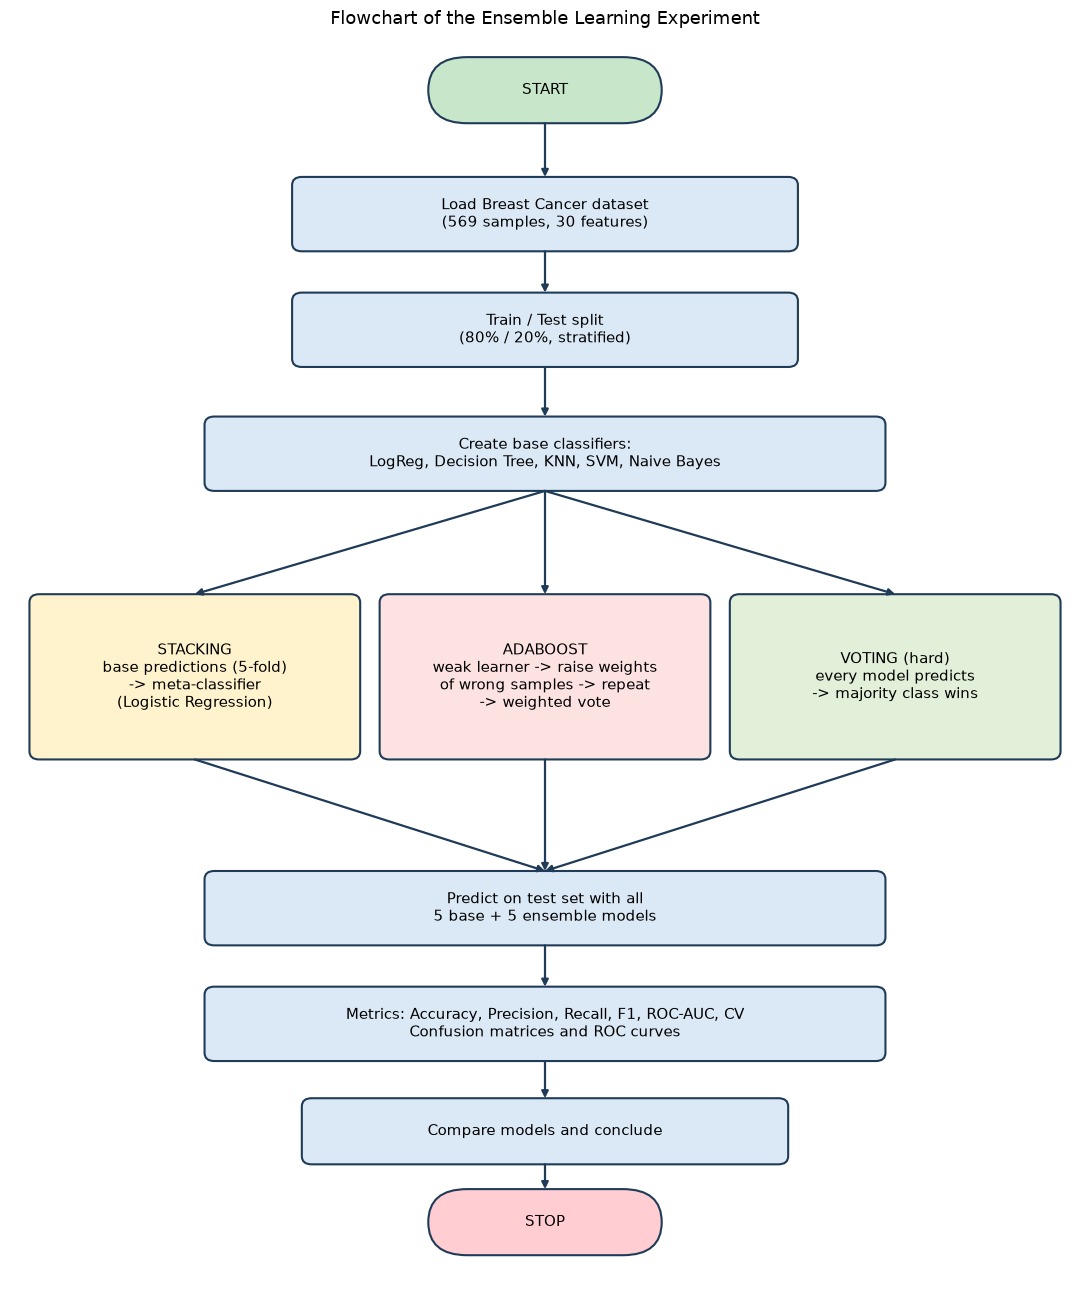

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 13))
ax.set_xlim(0, 11); ax.set_ylim(0, 14.5); ax.axis("off")

def box(x, y, w, h, text, color="#dbe9f6", rounded=False):
    style = "round,pad=0,rounding_size=0.4" if rounded else "round,pad=0,rounding_size=0.1"
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle=style, fc=color, ec="#1f3b57", lw=1.5))
    ax.text(x, y, text, ha="center", va="center", fontsize=10.5)
    return dict(x=x, top=y + h/2, bottom=y - h/2)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#1f3b57", shrinkA=0, shrinkB=0))

start = box(5.5, 13.5, 2.4, 0.8, "START", "#c8e6c9", True)
load  = box(5.5, 12.0, 5.2, 0.9, "Load Breast Cancer dataset\n(569 samples, 30 features)")
split = box(5.5, 10.6, 5.2, 0.9, "Train / Test split\n(80% / 20%, stratified)")
base  = box(5.5, 9.1, 7.0, 0.9, "Create base classifiers:\nLogReg, Decision Tree, KNN, SVM, Naive Bayes")
for a, b in [(start, load), (load, split), (split, base)]:
    arrow(5.5, a["bottom"], 5.5, b["top"])

stack = box(1.9, 6.4, 3.4, 2.0, "STACKING\nbase predictions (5-fold)\n-> meta-classifier\n(Logistic Regression)", "#fff3cd")
ada   = box(5.5, 6.4, 3.4, 2.0, "ADABOOST\nweak learner -> raise weights\nof wrong samples -> repeat\n-> weighted vote", "#fde2e2")
vote  = box(9.1, 6.4, 3.4, 2.0, "VOTING (hard)\nevery model predicts\n-> majority class wins", "#e2f0d9")
for s in (stack, ada, vote):
    arrow(5.5, base["bottom"], s["x"], s["top"])

pred = box(5.5, 3.6, 7.0, 0.9, "Predict on test set with all\n5 base + 5 ensemble models")
for s in (stack, ada, vote):
    arrow(s["x"], s["bottom"], 5.5, pred["top"])

met  = box(5.5, 2.2, 7.0, 0.9, "Metrics: Accuracy, Precision, Recall, F1, ROC-AUC, CV\nConfusion matrices and ROC curves")
comp = box(5.5, 0.9, 5.0, 0.8, "Compare models and conclude")
stop = box(5.5, -0.2, 2.4, 0.8, "STOP", "#ffcdd2", True)
for a, b in [(pred, met), (met, comp), (comp, stop)]:
    arrow(5.5, a["bottom"], 5.5, b["top"])

ax.set_ylim(-0.9, 14.2)

plt.title("Flowchart of the Ensemble Learning Experiment", fontsize=13)
plt.tight_layout(); plt.show()

## 7. Code (Implementation)

### 7.1 Importing the libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import StackingClassifier, AdaBoostClassifier, VotingClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             roc_curve, classification_report)

RANDOM_STATE = 42
sns.set_style("whitegrid")

### 7.2 Loading the dataset

In [ ]:
# Load the dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")      # 0 = malignant, 1 = benign

print("Shape of data   :", X.shape)
print("Classes         :", dict(zip(data.target_names, np.bincount(y))))
print("Missing values  :", int(X.isnull().sum().sum()))
X.head()

Shape of data   : (569, 30)
Classes         : {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Missing values  : 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### 7.3 Train and test split

In [ ]:
# 80% training, 20% testing (stratified so class ratio is the same in both)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 455
Testing samples : 114


### 7.4 Base models

In [ ]:
# Base classifiers.
# Scaling is added (inside a pipeline) for the models that depend on distance / gradients.
def get_base_models():
    return {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
        "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
        "SVM":                 make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
        "Naive Bayes":         GaussianNB(),
    }

base_models = get_base_models()
list(base_models.keys())

['Logistic Regression', 'Decision Tree', 'KNN', 'SVM', 'Naive Bayes']

### 7.5 Stacking ensemble
The meta-classifier here is Logistic Regression.

In [ ]:
# 1. STACKING ENSEMBLE
# Base learners give predictions; a meta-classifier (Logistic Regression) learns how to combine them.
# cv=5 means the meta-classifier is trained on out-of-fold predictions (prevents leakage).
stacking = StackingClassifier(
    estimators=list(get_base_models().items()),
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=5,
    stack_method="predict_proba",
    passthrough=False)
stacking

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('Logistic Regression', ...), ('Decision Tree', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...ndom_state=42)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'predict_proba'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used

### 7.6 AdaBoost ensemble
AdaBoost is built three times, each with a different base model: a decision stump (a tree of depth 1), a tree of depth 3, and logistic regression.

In [ ]:
# 2. ADABOOST ENSEMBLE
# AdaBoost is run with different chosen base classifiers (weak learners).
ada_models = {
    "AdaBoost (Decision Stump)":   AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
                                                      n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE),
    "AdaBoost (Depth-3 Tree)":     AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
                                                      n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE),
    "AdaBoost (Logistic Reg.)":    make_pipeline(StandardScaler(),   # scaler placed outside: AdaBoost needs a base model that accepts sample weights
                                                  AdaBoostClassifier(estimator=LogisticRegression(max_iter=1000),
                                                                     n_estimators=50, learning_rate=0.5, random_state=RANDOM_STATE)),
}
list(ada_models.keys())

['AdaBoost (Decision Stump)',
 'AdaBoost (Depth-3 Tree)',
 'AdaBoost (Logistic Reg.)']

### 7.7 Voting ensemble
Hard voting is used, so the final class is the one chosen by most models.

In [ ]:
# 3. VOTING ENSEMBLE (hard voting = majority vote of predicted class labels)
voting = VotingClassifier(estimators=list(get_base_models().items()), voting="hard")
voting

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('Logistic Regression', ...), ('Decision Tree', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000


### 7.8 Training and testing all the models
Every model is trained on the same training data and tested on the same unseen test data. Cross-validation accuracy is also calculated on the training data.

Hard voting does not give probabilities, so for its ROC curve only, the average probability of its member models is used.

In [ ]:
# Evaluate every model: train on training set, test on unseen test set, plus 5-fold CV accuracy.
all_models = {}
all_models.update({k: v for k, v in get_base_models().items()})
all_models["Stacking"] = stacking
all_models.update(ada_models)
all_models["Voting (Hard)"] = voting

group = {name: "Base" for name in base_models}
group.update({"Stacking": "Ensemble", "Voting (Hard)": "Ensemble"})
group.update({name: "Ensemble" for name in ada_models})

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows, fitted, probas, preds = [], {}, {}, {}
for name, model in all_models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring="accuracy")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    # hard voting has no probabilities, so use the decision score of the ensemble from its members
    if hasattr(model, "predict_proba") and name != "Voting (Hard)":
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = np.mean([m.predict_proba(X_test)[:, 1] for m in model.estimators_], axis=0)
    fitted[name], preds[name], probas[name] = model, y_pred, y_score
    rows.append({
        "Model": name, "Type": group[name],
        "CV Accuracy": cv_scores.mean(), "CV Std": cv_scores.std(),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_score),
    })

results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,Type,CV Accuracy,CV Std,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,,,,
Logistic Regression,Base,0.9780,0.0098,0.9825,0.9861,0.9861,0.9861,0.9954
Decision Tree,Base,0.9231,0.0120,0.9211,0.9565,0.9167,0.9362,0.9163
KNN,Base,0.9626,0.0204,0.9737,0.9600,1.0000,0.9796,0.9884
SVM,Base,0.9692,0.0146,0.9825,0.9861,0.9861,0.9861,0.9950
Naive Bayes,Base,0.9407,0.0247,0.9386,0.9452,0.9583,0.9517,0.9878
Stacking,Ensemble,0.9736,0.0149,0.9737,0.9726,0.9861,0.9793,0.9944
AdaBoost (Decision Stump),Ensemble,0.9692,0.0146,0.9561,0.9467,0.9861,0.9660,0.9848
AdaBoost (Depth-3 Tree),Ensemble,0.9780,0.0120,0.9561,0.9589,0.9722,0.9655,0.9907
AdaBoost (Logistic Reg.),Ensemble,0.9648,0.0128,0.9474,0.9853,0.9306,0.9571,0.9932


### 7.9 Ranking the models

In [ ]:
results_sorted = results.sort_values("F1-Score", ascending=False)
display(results_sorted.round(4))

print("Best base model     :", results[results.Type=="Base"]["F1-Score"].idxmax(),
      "->", round(results[results.Type=="Base"]["F1-Score"].max(), 4))
print("Best ensemble model :", results[results.Type=="Ensemble"]["F1-Score"].idxmax(),
      "->", round(results[results.Type=="Ensemble"]["F1-Score"].max(), 4))

,Type,CV Accuracy,CV Std,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,,,,
Logistic Regression,Base,0.9780,0.0098,0.9825,0.9861,0.9861,0.9861,0.9954
SVM,Base,0.9692,0.0146,0.9825,0.9861,0.9861,0.9861,0.9950
KNN,Base,0.9626,0.0204,0.9737,0.9600,1.0000,0.9796,0.9884
Stacking,Ensemble,0.9736,0.0149,0.9737,0.9726,0.9861,0.9793,0.9944
Voting (Hard),Ensemble,0.9758,0.0108,0.9737,0.9726,0.9861,0.9793,0.9927
AdaBoost (Decision Stump),Ensemble,0.9692,0.0146,0.9561,0.9467,0.9861,0.9660,0.9848
AdaBoost (Depth-3 Tree),Ensemble,0.9780,0.0120,0.9561,0.9589,0.9722,0.9655,0.9907
AdaBoost (Logistic Reg.),Ensemble,0.9648,0.0128,0.9474,0.9853,0.9306,0.9571,0.9932
Naive Bayes,Base,0.9407,0.0247,0.9386,0.9452,0.9583,0.9517,0.9878


Best base model     : Logistic Regression -> 0.9861
Best ensemble model : Stacking -> 0.9793


### 7.10 Graphs

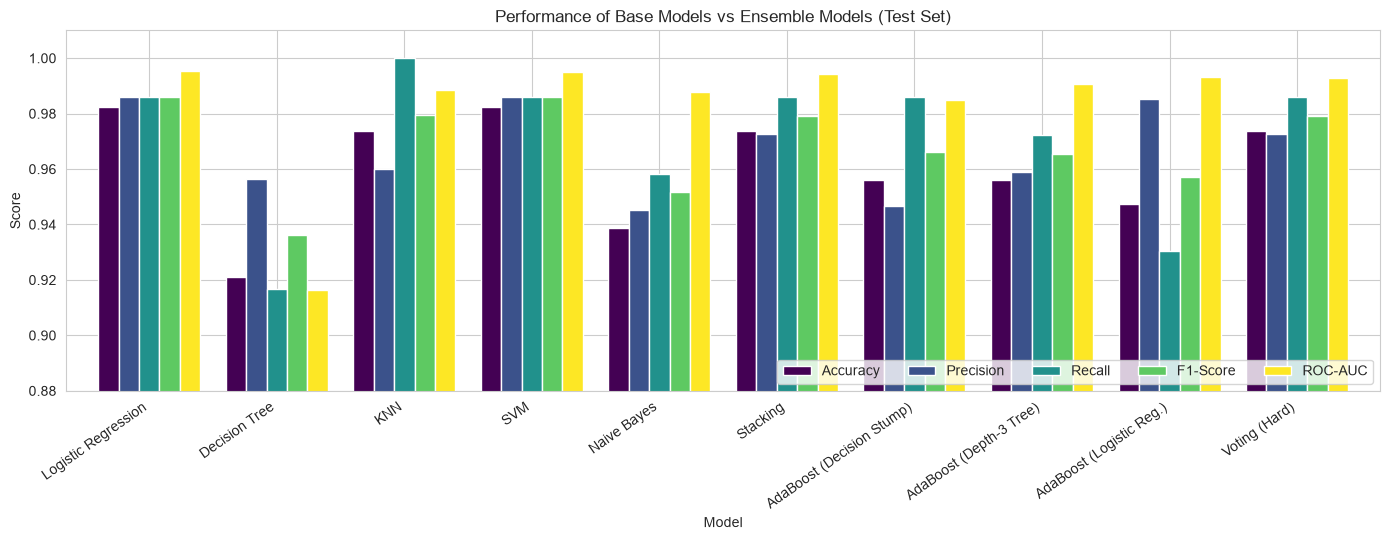

In [ ]:
# Bar chart comparison of the main metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
ax = results[metrics].plot(kind="bar", figsize=(14, 5.5), width=0.8, colormap="viridis")
ax.set_title("Performance of Base Models vs Ensemble Models (Test Set)")
ax.set_ylabel("Score")
ax.set_ylim(0.88, 1.01)
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.show()

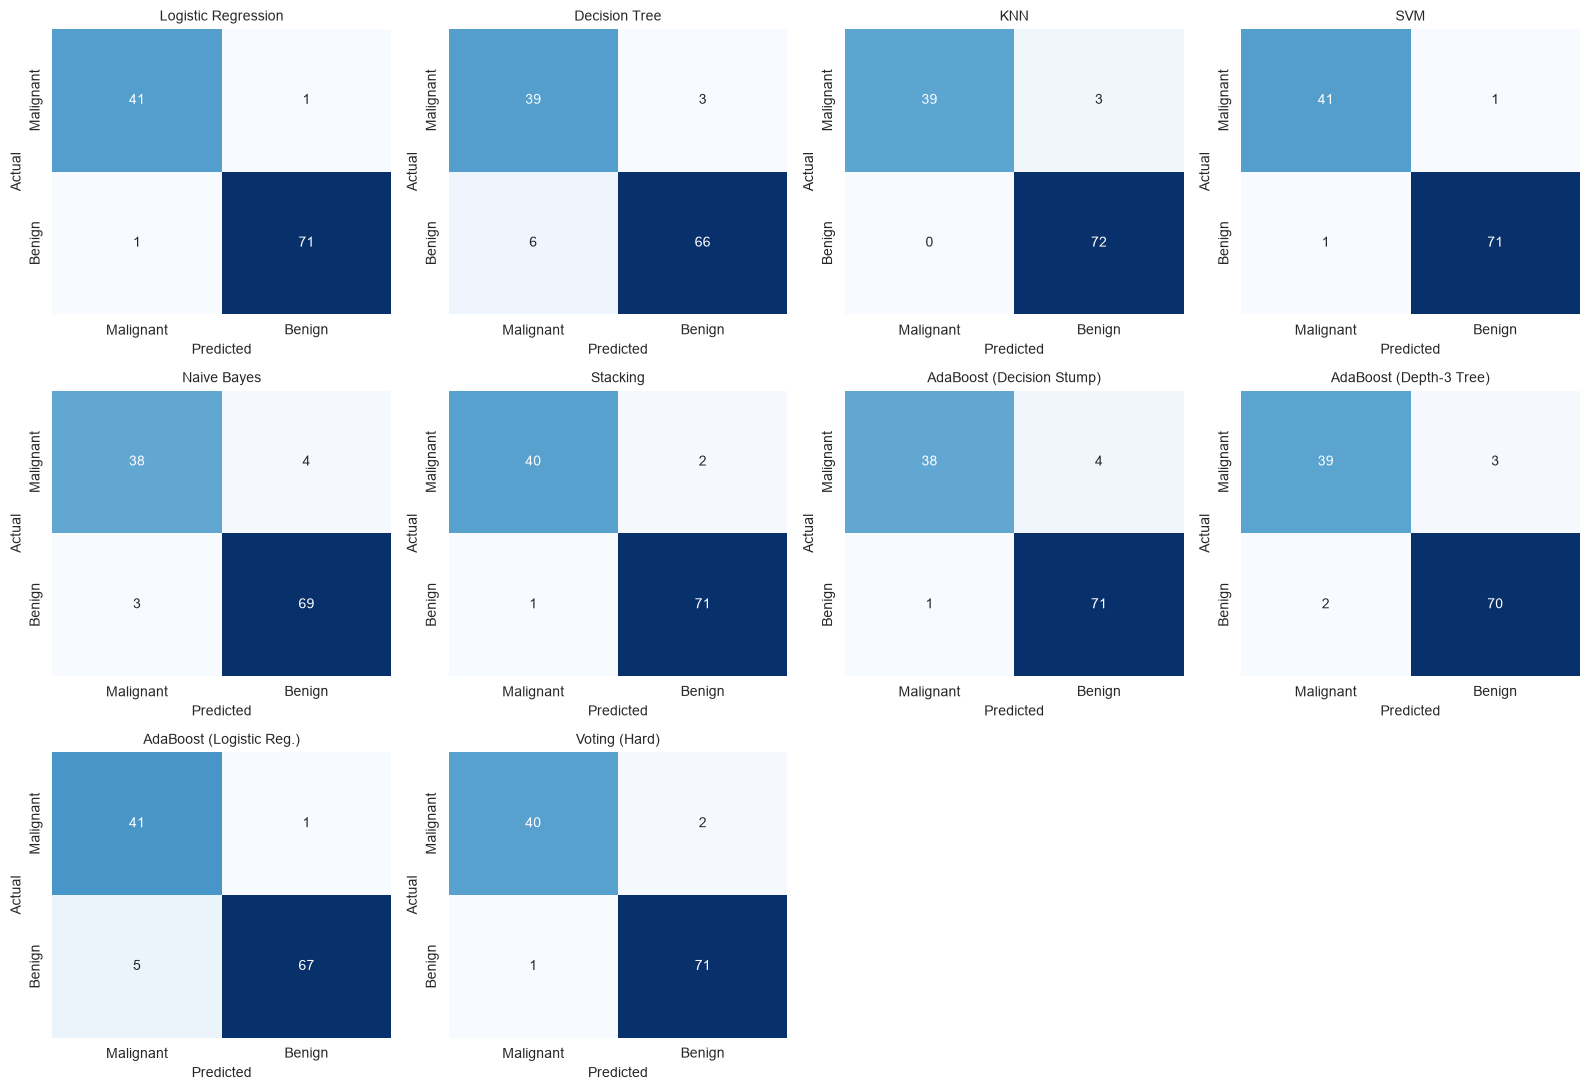

In [ ]:
# Confusion matrices
names = list(all_models.keys())
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, name in zip(axes.ravel(), names):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Malignant", "Benign"], yticklabels=["Malignant", "Benign"])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

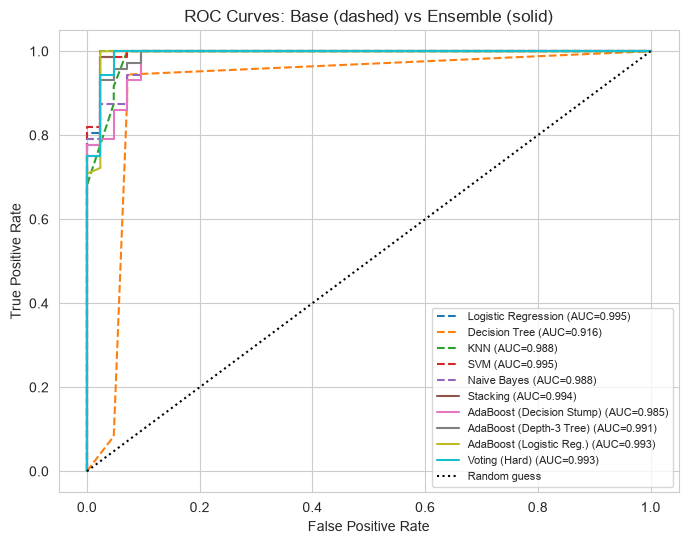

In [ ]:
# ROC curves
plt.figure(figsize=(8, 6))
for name in names:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    style = "-" if group[name] == "Ensemble" else "--"
    plt.plot(fpr, tpr, style, label=f"{name} (AUC={roc_auc_score(y_test, probas[name]):.3f})")
plt.plot([0, 1], [0, 1], "k:", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Base (dashed) vs Ensemble (solid)")
plt.legend(fontsize=8, loc="lower right")
plt.show()

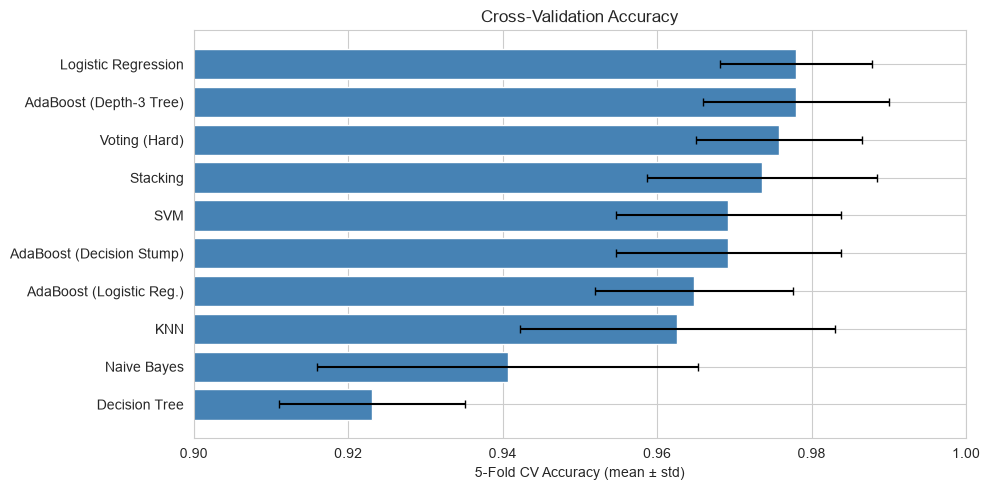

In [ ]:
# Stability of each model across the 5 cross-validation folds
cv_df = results[["CV Accuracy", "CV Std"]].sort_values("CV Accuracy", ascending=False)
plt.figure(figsize=(10, 5))
plt.barh(cv_df.index, cv_df["CV Accuracy"], xerr=cv_df["CV Std"], color="steelblue", capsize=3)
plt.xlim(0.90, 1.0)
plt.xlabel("5-Fold CV Accuracy (mean ± std)")
plt.title("Cross-Validation Accuracy")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 7.11 Class-wise report of the best ensemble

In [ ]:
# Detailed report for the best ensemble
best_ens = results[results.Type=="Ensemble"]["F1-Score"].idxmax()
print("Classification report for:", best_ens)
print(classification_report(y_test, preds[best_ens], target_names=data.target_names))

Classification report for: Stacking
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



### 7.12 Repeating on 10 random splits
The test set has only 114 samples, so one extra mistake changes the accuracy by almost 1%. To avoid depending on a single split, the experiment is repeated with 10 different splits and the F1-scores are averaged.

In [ ]:
# Extra check: repeat with 10 different random splits so the conclusion does not depend on one lucky split
from sklearn.base import clone
repeat_scores = {name: [] for name in all_models}
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)
    for name, model in all_models.items():
        m = clone(model).fit(Xtr, ytr)
        repeat_scores[name].append(f1_score(yte, m.predict(Xte)))

rep = pd.DataFrame({"Mean F1": {k: np.mean(v) for k, v in repeat_scores.items()},
                    "Std F1":  {k: np.std(v)  for k, v in repeat_scores.items()}}).sort_values("Mean F1", ascending=False)
rep.round(4)

,Mean F1,Std F1
Logistic Regression,0.9854,0.0080
AdaBoost (Decision Stump),0.9820,0.0113
KNN,0.9815,0.0043
AdaBoost (Depth-3 Tree),0.9806,0.0088
Voting (Hard),0.9806,0.0083
Stacking,0.9798,0.0081
SVM,0.9798,0.0087
AdaBoost (Logistic Reg.),0.9762,0.0116
Naive Bayes,0.9587,0.0136
Decision Tree,0.9512,0.0219


## 8. Result Analysis

### 8.1 Results on the single test split
The test set has 114 samples. These are the main numbers from the comparison table above (accuracy, F1-score and ROC-AUC).

Logistic Regression: 0.9825, 0.9861, 0.9954  
SVM: 0.9825, 0.9861, 0.9950  
KNN: 0.9737, 0.9796, 0.9884  
Stacking: 0.9737, 0.9793, 0.9944  
Voting (hard): 0.9737, 0.9793, 0.9927  
AdaBoost with decision stump: 0.9561, 0.9660, 0.9848  
AdaBoost with depth-3 tree: 0.9561, 0.9655, 0.9907  
AdaBoost with logistic regression: 0.9474, 0.9571, 0.9932  
Naive Bayes: 0.9386, 0.9517, 0.9878  
Decision Tree: 0.9211, 0.9362, 0.9163  

### 8.2 What we observe
The ensembles did better than the weak single models. Stacking and Voting both reached 97.4% accuracy, while the Decision Tree got 92.1% and Naive Bayes got 93.9%. All three AdaBoost models also did better than the single Decision Tree, even the one that uses just a stump, which is a very weak model on its own.

The ensembles did not beat the best single models in this experiment. Logistic Regression and SVM got 98.3% accuracy, which is about one sample better than Stacking and Voting on a test set of 114. That is too small a gap to call one of them better. The dataset is almost linearly separable, so even a simple linear model is already close to the maximum, and there is not much left for an ensemble to improve.

Stacking and Voting were the best of the ensembles. Both made 3 mistakes out of 114. Stacking has a slightly higher ROC-AUC (0.9944 against 0.9927), which is expected because its meta-classifier works with probabilities and not only with the class labels.

AdaBoost was the weakest group of ensembles on this split. One possible reason is that boosting keeps increasing the weight of hard samples, and some of them may be noisy, but this was not tested separately. It is also worth noting that AdaBoost with the depth-3 tree had the highest cross-validation accuracy (0.978, same as Logistic Regression), so the single split does not tell the whole story.

For a medical problem like this, the dangerous mistake is calling a malignant tumour benign. The class-wise report of the Stacking model shows a recall of 0.95 for malignant cases, which means 2 of the 42 malignant cases were missed. The best models had recall of about 0.97 to 1.00 for the benign class, while the Decision Tree (0.917) and AdaBoost with logistic regression (0.931) were lower.

In the cross-validation results, Voting (std 0.011) and AdaBoost with the depth-3 tree (0.012) were more stable than Naive Bayes (0.025).

### 8.3 Results on 10 random splits
Mean F1-score over 10 splits, from highest to lowest: Logistic Regression 0.985, AdaBoost with stump 0.982, KNN 0.982, AdaBoost with depth-3 tree 0.981, Voting 0.981, Stacking 0.980, SVM 0.980, AdaBoost with logistic regression 0.976, Naive Bayes 0.959, Decision Tree 0.951.

The order is quite different from the single split. For example, AdaBoost with stumps moved from 6th place to 2nd. The top eight models are all within about 1% of each other, so we cannot say that any one of them is really better than the others. Two things are clear though. All the ensembles stay in the top group and none of them drops down to the level of the Decision Tree or Naive Bayes. And with an ensemble we do not have to guess in advance which single model will be the best, which is useful in practice.

### 8.4 When to use which ensemble
Voting is a good choice when you already have a few decent models that are different from each other and you want a simple and quick improvement. It does not help much when the models are almost the same, or when one model is much worse than the others.

Stacking is a good choice when you have several strong and different models, enough data, and you want the best possible accuracy. It is slower to train and harder to explain, and it is not a good idea for very small datasets.

AdaBoost is a good choice when the base model is simple, such as a stump or a shallow tree, and the data is clean. It can struggle when there are many outliers or wrong labels, because it keeps giving more weight to those samples.

### 8.5 Limitations
Only one dataset was used and it is small and easy, so the benefit of ensembles would probably be larger on harder or noisier data. The hyper-parameters were chosen by hand and not tuned. Also, differences of one or two samples on a 114-sample test set are not statistically meaningful.

## 9. Conclusion
In this experiment Stacking, AdaBoost and Voting ensembles were built and compared with five single classifiers on the Breast Cancer dataset using accuracy, precision, recall, F1-score, ROC-AUC, confusion matrices and cross-validation.

All the ensembles reached between 94.7% and 97.4% test accuracy and did clearly better than the weakest single models. Stacking and hard Voting were the best ensembles, with 97.4% accuracy and an F1-score of 0.979.

On this dataset the ensembles were **not** better than the best single models, Logistic Regression and SVM, which reached 98.3%. The difference was about one test sample, and the repeated test on 10 splits showed that the top models are practically equal. The real advantage of the ensembles here is that they stay near the top without needing us to find the best single model first.

In short, use Voting for a quick and simple improvement, Stacking when you want the best accuracy and have enough data, and AdaBoost when you are working with simple weak models on clean data.

Some ways this work can be taken further:
1. Tune the hyper-parameters of the base models, the meta-classifier and the AdaBoost learning rate using grid search.
2. Try soft voting and weighted voting, and compare with Random Forest and gradient boosting.
3. Test on larger, noisier, imbalanced or multi-class datasets, where ensembles usually help more.
4. Use repeated cross-validation along with a statistical test to confirm the differences between models.
5. Measure the training and prediction time, since ensembles need more computation.
6. Add feature importance or SHAP to explain the predictions, which matters for medical use.
7. Try other meta-classifiers such as Random Forest, or stack in more than one level.